##🥡 **Set form start**

In [69]:

# architecture type
ARCHITECTURE = 'LSTM'
BIDIRECTIONAL = True
# Training configuration
LEARNING_RATE = 1e-3
EPOCHS = 200
PATIENCE = 20
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE =64
# Architecture
HIDDEN_LAYERS = 2        # Hidden layers
HIDDEN_SIZE = 128       # Neurons per layer
# Regularisation
DROPOUT_RATE = 0.3           # Dropout probability
L1_LAMBDA = 0.00000          # L1 penalty
L2_LAMBDA = 1e-4          # L2 penalty
GAMMA = 1.75
# Define the window size
WINDOW_SIZE = 32
# Define the stride for overlapping windows
STRIDE = 4
# its how many data we "skip"
# Define the number of users for validation and test sets
N_VAL_USERS = 100 # You can change this number

# Use pain_survey columns?
PAIN_SURVEY_COLUMNS = True

JITTERING = True
ATTENTION = True
RELU = False

EXPERIMENT_NAME=f"{ARCHITECTURE}_{BIDIRECTIONAL}_ws{WINDOW_SIZE}_bs{BATCH_SIZE}_stride{STRIDE}_lr{LEARNING_RATE}_gamma{GAMMA}_l1{L1_LAMBDA}_l2{L2_LAMBDA}_patience{PATIENCE}_hidden{HIDDEN_SIZE}_layers{HIDDEN_LAYERS}_dropout{DROPOUT_RATE}_j{JITTERING}_a{ATTENTION}_relu{RELU}"

#giorni/ore/settimane/mesi?
TIME= 6.4


## 🌏 **Google connect/Data loading**

### 🌐 **Google Drive Connection**

In [2]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/AN2DL-Challenge1"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/AN2DL-Challenge1


### **Loading dataset**

In [70]:
# from google.colab import files
# files.upload()

# !mkdir -p ~/.kaggle
# !mv kaggle.json ~/.kaggle/
# !chmod 600 ~/.kaggle/kaggle.json

# !pip install -q kaggle
# !kaggle competitions download -c an2dl2526c1

# !unzip an2dl2526c1.zip -d dataset



later on, data are loaded and managed in next section, need to see for kaggle

## 📚 **Import Libraries**

In [4]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np
import datetime


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.8.0+cu126
Device: cuda


## ❗**First look at data (necessary to run)**


In [71]:


#read the dataset

df = pd.read_csv('dataset/pirate_pain_train.csv')
dfTest = pd.read_csv('dataset/pirate_pain_test.csv')

# replace with  pirate? 1:0, i just wanted to
df['has_any_disability'] = ((df['n_legs'] != 'two') | (df['n_hands'] != 'two') | (df['n_eyes'] != 'two')).astype(int)
dfTest['has_any_disability'] = ((dfTest['n_legs'] != 'two') | (dfTest['n_hands'] != 'two') | (dfTest['n_eyes'] != 'two')).astype(int)

# Calculate 'hour_of_day' assuming 'time' unit is an hour and loops every 24 hours
df['hour_of_day'] = df['time'] % TIME
dfTest['hour_of_day'] = dfTest['time'] % TIME

# Apply sine and cosine transformations for cyclical representation
df['hour_sin'] = np.sin(2 * np.pi * df['hour_of_day'] / TIME)
df['hour_cos'] = np.cos(2 * np.pi * df['hour_of_day'] / TIME)
dfTest['hour_sin'] = np.sin(2 * np.pi * dfTest['hour_of_day'] / TIME)
dfTest['hour_cos'] = np.cos(2 * np.pi * dfTest['hour_of_day'] / TIME)

#turn float64 into float32, to speed up
joint_columns = [col for col in df.columns if col.startswith('joint_')]
df[joint_columns] = df[joint_columns].astype(np.float32)
df.drop['joint_30']

I know I know I should have followed the instuctions

In [72]:
# Read the labels CSV file into a new DataFrame
labels_df = pd.read_csv('dataset/pirate_pain_train_labels.csv')

# Display the first few rows of the labels DataFrame to inspect its structure
print("Labels DataFrame shape:", labels_df.shape)
display(labels_df.head())


Labels DataFrame shape: (661, 2)


,sample_index,label
0,0,no_pain
1,1,no_pain
2,2,low_pain
3,3,no_pain
4,4,no_pain


In [73]:
# Merge the main DataFrame with the labels DataFrame based on 'sample_index'
# Use a left merge to keep all rows from the original df and add the corresponding labels
df = pd.merge(df, labels_df, on='sample_index', how='left')

# Display the first few rows of the merged DataFrame to verify
print("Merged DataFrame shape:", df.shape)
display(df.head())

Merged DataFrame shape: (105760, 45)


,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_26,joint_27,joint_28,joint_29,joint_30,has_any_disability,hour_of_day,hour_sin,hour_cos,label
0,0,0,2,0,2,1,two,two,two,1.094705,...,0.017592,0.013508,0.026798,0.027815,0.5,0,0.0,0.000000,1.000000,no_pain
1,0,1,2,2,2,2,two,two,two,1.135183,...,0.013352,0.000000,0.013377,0.013716,0.5,0,1.0,0.831470,0.555570,no_pain
2,0,2,2,0,2,2,two,two,two,1.080745,...,0.016225,0.008110,0.024097,0.023105,0.5,0,2.0,0.923880,-0.382683,no_pain
3,0,3,2,2,2,2,two,two,two,0.938017,...,0.011832,0.007450,0.028613,0.024648,0.5,0,3.0,0.195090,-0.980785,no_pain
4,0,4,2,2,2,2,two,two,two,1.090185,...,0.005360,0.002532,0.033026,0.025328,0.5,0,4.0,-0.707107,-0.707107,no_pain


In [74]:
if JITTERING:
    def add_noise(df, columns, noise_level=0.01, random_seed=None):
        if random_seed is not None:
            np.random.seed(random_seed)

        df_copy = df.copy()
        for col in columns:
            noise = np.random.normal(0, noise_level, df_copy[col].shape)
            df_copy[col] = df_copy[col] + noise
        return df_copy

    # Apply jittering to the training data. This is done to augment the training data
    # and improve the robustness of the model by making it less sensitive to small
    # variations in the input data.
    joint_columns = [col for col in df.columns if col.startswith('joint_')]
    df = add_noise(df, joint_columns, noise_level=0.005, random_seed=SEED)

## one hot encode the pain survey data

In [75]:
pain_survey_columns = ['pain_survey_1', 'pain_survey_2', 'pain_survey_3', 'pain_survey_4']

# One-hot encode the pain survey data for df
df = pd.get_dummies(df, columns=pain_survey_columns, prefix=pain_survey_columns, dtype=int)

# One-hot encode the pain survey data for dfTest
dfTest = pd.get_dummies(dfTest, columns=pain_survey_columns, prefix=pain_survey_columns, dtype=int)

print("DataFrame after one-hot encoding:")
display(df.head())
print("Test DataFrame after one-hot encoding:")
display(dfTest.head())

DataFrame after one-hot encoding:


,sample_index,time,n_legs,n_hands,n_eyes,joint_00,joint_01,joint_02,joint_03,joint_04,...,pain_survey_1_2,pain_survey_2_0,pain_survey_2_1,pain_survey_2_2,pain_survey_3_0,pain_survey_3_1,pain_survey_3_2,pain_survey_4_0,pain_survey_4_1,pain_survey_4_2
0,0,0,two,two,two,1.097189,0.984786,1.017642,1.002106,0.973542,...,1,1,0,0,0,0,1,0,1,0
1,0,1,two,two,two,1.134492,1.015161,0.996973,1.051653,1.012258,...,1,0,0,1,0,0,1,0,0,1
2,0,2,two,two,two,1.083983,0.968801,1.009239,0.987581,0.987158,...,1,1,0,0,0,0,1,0,0,1
3,0,3,two,two,two,0.945632,1.079477,0.996389,0.988036,0.924082,...,1,0,0,1,0,0,1,0,0,1
4,0,4,two,two,two,1.089014,1.036271,1.010139,0.968746,1.005238,...,1,0,0,1,0,0,1,0,0,1


Test DataFrame after one-hot encoding:


,sample_index,time,n_legs,n_hands,n_eyes,joint_00,joint_01,joint_02,joint_03,joint_04,...,pain_survey_1_2,pain_survey_2_0,pain_survey_2_1,pain_survey_2_2,pain_survey_3_0,pain_survey_3_1,pain_survey_3_2,pain_survey_4_0,pain_survey_4_1,pain_survey_4_2
0,0,0,two,two,two,0.842535,0.845934,0.573001,0.395143,0.302871,...,1,0,0,1,0,0,1,0,0,1
1,0,1,two,two,two,0.898836,0.814810,0.629339,0.469420,0.247027,...,1,0,0,1,0,0,1,0,0,1
2,0,2,two,two,two,0.957765,0.890690,0.608661,0.444819,0.295657,...,1,0,0,1,0,0,1,0,0,1
3,0,3,two,two,two,0.832596,0.751427,0.605583,0.504279,0.236913,...,0,0,0,1,0,0,1,0,0,1
4,0,4,two,two,two,0.805971,0.810004,0.565170,0.514796,0.269761,...,1,0,0,1,0,0,1,1,0,0


## 🥦 **Data Processing (obs run)**

In [76]:
# Get unique user IDs
unique_users = df['sample_index'].unique()

# Get the label and has_any_disability for each unique user
# Create a DataFrame where index is sample_index and values are label and has_any_disability
user_level_strat_info = df.drop_duplicates(subset=['sample_index']).set_index('sample_index')[['label', 'has_any_disability']]

# Create a combined stratification key
user_level_strat_info['combined_strat_key'] = user_level_strat_info['label'].astype(str) + '_' + user_level_strat_info['has_any_disability'].astype(str)

# Get the stratification labels as a Series for unique users
stratify_series = user_level_strat_info.loc[unique_users]['combined_strat_key']

# Identify strata with only one member (these cause ValueError in train_test_split)
strat_counts = stratify_series.value_counts()
single_member_strata_keys = strat_counts[strat_counts == 1].index.tolist()

# Separate users into 'splittable' (can be stratified) and 'unsplittable' (single-member strata)
splittable_users_mask = ~stratify_series.isin(single_member_strata_keys)
splittable_users = unique_users[splittable_users_mask]
unsplittable_users = unique_users[~splittable_users_mask]

# Get stratify labels for the splittable users
stratify_labels_for_splittable = stratify_series.loc[splittable_users].values

# Calculate a proportional test_size based on N_VAL_USERS and total unique users
# This makes the split more robust when dealing with varying class sizes
test_size_ratio = N_VAL_USERS / len(unique_users)

# Perform stratified split on the splittable users
# Only attempt split if there are enough splittable users and valid strata
if len(splittable_users) > 1 and len(np.unique(stratify_labels_for_splittable)) > 1:
    train_users_main, val_users_main = train_test_split(
        splittable_users,
        test_size=test_size_ratio, # Use a proportion for test_size
        stratify=stratify_labels_for_splittable,
        random_state=SEED
    )
else:
    # If not enough splittable users for stratified split, put them all in train
    train_users_main = splittable_users
    val_users_main = np.array([])

# Combine the results, adding unsplittable users (single-member strata) to the training set
train_users = np.concatenate((train_users_main, unsplittable_users))
val_users = val_users_main

# Split the dataset into training, validation, and test sets based on user IDs
df_train = df[df['sample_index'].isin(train_users)]
df_val = df[df['sample_index'].isin(val_users)]
df_test = dfTest

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')
print(f'Test set shape: {df_test.shape}')

Training set shape: (89760, 53)
Validation set shape: (16000, 53)
Test set shape: (211840, 52)


In [77]:
# Initialise a dictionary to count occurrences of each activity in the training set
training_labels = {
   'no_pain':0,
   'low_pain':0,
   'high_pain':0
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = df_train[df_train['sample_index'] == id]['label'].values[0]
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'no_pain': 433, 'low_pain': 80, 'high_pain': 48}


In [78]:
# Initialise a dictionary to count occurrences of each activity in the validation set
val_labels = {
   'no_pain':0,
   'low_pain':0,
   'high_pain':0
}

# Count occurrences of each activity for unique IDs in the validation set
for id in df_val['sample_index'].unique():
    label = df_val[df_val['sample_index'] == id]['label'].values[0]
    val_labels[label] += 1

# Print the distribution of validation labels
print('Validation labels:', val_labels)

Validation labels: {'no_pain': 78, 'low_pain': 14, 'high_pain': 8}


In [79]:
label_mapping = {
     'no_pain':0,
   'low_pain':1,
   'high_pain':2
}

# Map activity names to integers in the training set
df_train['label'] = df_train['label'].map(label_mapping)

# Map activity names to integers in the validation set
df_val['label'] = df_val['label'].map(label_mapping)

# Create the inverse mapping immediately after label_mapping
label_inverse_mapping = {v: k for k, v in label_mapping.items()}

'''# Map activity names to integers in the test set
df_test['label'] = df_test['label'].map(label_mapping)'''

"# Map activity names to integers in the test set\ndf_test['label'] = df_test['label'].map(label_mapping)"

In [80]:

# Define the columns to be normalised
scale_columns = []
for col in df_train.columns:
    if col.startswith('joint_'):
        scale_columns.append(col)

# Calculate the minimum and maximum values from the training data only
mins = df_train[scale_columns].min()
maxs = df_train[scale_columns].max()

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    col_min = mins[column]
    col_max = maxs[column]

    # Check for constant columns to prevent division by zero, which would create NaNs
    if col_max == col_min:
        print(f"Warning: Column '{column}' has constant values in df_train. Setting to 0 after 'normalization'.")
        df_train[column] = 0.0
        df_val[column] = 0.0
        df_test[column] = 0.0
    else:
        # Normalise the training set
        df_train[column] = (df_train[column] - col_min) / (col_max - col_min)

        # Normalise the validation set
        df_val[column] = (df_val[column] - col_min) / (col_max - col_min)

        # Normalise the test set
        df_test[column] = (df_test[column] - col_min) / (col_max - col_min)

In [81]:

def build_sequences(df, window=40, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Check if the 'label' column exists in the DataFrame
    has_labels = 'label' in df.columns

    # Define feature columns dynamically based on the dataframe structure
    feature_columns = [col for col in df.columns if col.startswith('joint_')] + \
                      ['has_any_disability','hour_sin','hour_cos']

    if PAIN_SURVEY_COLUMNS:
          feature_columns += [col for col in df.columns if col.startswith('pain_survey_')]


    num_features = len(feature_columns)

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][feature_columns].values

        # Retrieve the activity label for the current ID if labels are available
        current_label = None
        if has_labels:
            current_label = df[df['sample_index'] == id]['label'].values[0]
        else:
            # For test data where labels are not available, use a dummy value (e.g., 0)
            # This placeholder will be replaced by predictions later.
            current_label = 0

        # Calculate padding length to ensure full windows
        padding_len = (window - (len(temp) % window)) % window

        # Create zero padding and concatenate with the data
        padding = np.zeros((padding_len, num_features), dtype='float32')
        temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            labels.append(current_label) # Append the actual label or the dummy label
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels

In [82]:

# Generate sequences and labels for the training set
X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the validation set
X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the test set
X_test, y_test = build_sequences(df_test, WINDOW_SIZE, STRIDE)


In [83]:
# Define the input shape based on the training data
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

In [84]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
# Explicitly cast to .float() to ensure torch.float32 type for all input tensors
train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))
test_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))

### experimenting:


In [85]:
# here I need to create a weight vector with weights in correspondence of the train_ds samples
weights_vector = []

# Get user-level information (has_any_disability and original string label) from the full 'df' DataFrame
# This ensures we get the original string label before df_train's labels were mapped to integers.
user_level_info_df = df[df['sample_index'].isin(df_train['sample_index'].unique())]
user_level_info_df = user_level_info_df[['sample_index', 'has_any_disability', 'label']].drop_duplicates(subset=['sample_index']).set_index('sample_index')

# Calculate weights for 'pirate' users
pirate_users_info = user_level_info_df[user_level_info_df['has_any_disability'] == 1]
pirate_label_counts = pirate_users_info['label'].value_counts()
total_pirate_users = pirate_label_counts.sum()
# Calculate inverse frequency weights
weights_pirate = {
    label: (1.0 / count) * (total_pirate_users / len(pirate_label_counts))
    for label, count in pirate_label_counts.items()
}
# Normalize the weights so they sum to 1 for each category (optional, but good practice)
sum_weights_pirate = sum(weights_pirate.values())
weights_pirate = {label: weight / sum_weights_pirate for label, weight in weights_pirate.items()}


# Calculate weights for 'no_pirate' users
no_pirate_users_info = user_level_info_df[user_level_info_df['has_any_disability'] == 0]
no_pirate_label_counts = no_pirate_users_info['label'].value_counts()
total_no_pirate_users = no_pirate_label_counts.sum()
# Calculate inverse frequency weights
weights_no_pirate = {
    label: (1.0 / count) * (total_no_pirate_users / len(no_pirate_label_counts))
    for label, count in no_pirate_label_counts.items()
}
# Normalize the weights so they sum to 1 for each category (optional, but good practice)
sum_weights_no_pirate = sum(weights_no_pirate.values())
weights_no_pirate = {label: weight / sum_weights_no_pirate for label, weight in weights_no_pirate.items()}


# Reconstruct the mapping from sequence index in train_ds to its original sample_index (user_id)
# This follows the logic of the build_sequences function to identify which user each sequence belongs to.
original_sample_indices_for_train_sequences = []
for user_id in df_train['sample_index'].unique():
    # Get the length of the data for this user from df_train
    user_data_len = len(df_train[df_train['sample_index'] == user_id])

    # Padding logic from build_sequences function (using global WINDOW_SIZE and STRIDE)
    padding_len = (WINDOW_SIZE - (user_data_len % WINDOW_SIZE)) % WINDOW_SIZE
    total_len_after_padding = user_data_len + padding_len

    idx = 0
    while idx + WINDOW_SIZE <= total_len_after_padding:
        original_sample_indices_for_train_sequences.append(user_id)
        idx += STRIDE

# Verify the length match, crucial for WeightedRandomSampler
if len(original_sample_indices_for_train_sequences) != len(train_ds):
    raise ValueError(
        "Mismatch in number of sequences for weight calculation and actual train_ds length.\n"
        "This indicates an inconsistency in how sequences are generated or accounted for."
        f"Expected {len(train_ds)} sequences, but got {len(original_sample_indices_for_train_sequences)}."
    )


# Now iterate through the reconstructed sequence-to-user mapping and assign weights
for sequence_original_sample_index in original_sample_indices_for_train_sequences:
    # Retrieve user-level attributes using the original sample_index
    has_disability = user_level_info_df.loc[sequence_original_sample_index, 'has_any_disability']
    original_string_label = user_level_info_df.loc[sequence_original_sample_index, 'label']

    # Determine the weight based on disability status and the original string label
    if has_disability:
        weight = weights_pirate[original_string_label]
    else:
        weight = weights_no_pirate[original_string_label]

    weights_vector.append(weight)

# Convert the list of weights to a PyTorch tensor
weights_vector = torch.tensor(weights_vector, dtype=torch.float32)

print(weights_vector)

tensor([0.0651, 0.0651, 0.0651,  ..., 0.0651, 0.0651, 0.0651])


### non experimenting

In [86]:
def make_loader(ds, batch_size, shuffle, drop_last, sampler=None):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = cpu_cores-1

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle and sampler is None,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=5,  # Load 4 batches ahead
        sampler=sampler
    )

In [87]:
# Create a WeightedRandomSampler for the training data
# This sampler uses the pre-calculated weights_vector to balance classes during training
weighted_sampler = WeightedRandomSampler(weights=weights_vector, num_samples=len(train_ds), replacement=True)

# Create data loaders with different settings for each phase
#train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False), sampler=weighted_sampler)
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [88]:
# Get one batch from the training data loader
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([64, 32, 46])
Labels batch shape: torch.Size([64])


## **Exploring Focal Loss**

In [89]:
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

        if isinstance(alpha, (float, int)): # Handle scalar alpha
            self.alpha = torch.tensor([alpha, 1 - alpha])
        if isinstance(alpha, torch.Tensor):
            self.alpha = alpha.to(device)

    def forward(self, inputs, targets):
        BCE_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)
        F_loss = self.alpha[targets] * (1-pt)**self.gamma * BCE_loss

        if self.reduction == 'mean':
            return F_loss.mean()
        elif self.reduction == 'sum':
            return F_loss.sum()
        else:
            return F_loss

print("FocalLoss class defined.")

FocalLoss class defined.


## 🛠 **Finally building the model (Run and don't modify)**

In [90]:
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, nn.LSTM, or nn.LayerNorm layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear, LayerNorm)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM, nn.LayerNorm)): # Added nn.LayerNorm here
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)



In [91]:
class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='LSTM',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=True,
            dropout_rate=0.2,
            use_relu=False, # Add this parameter with a default value
            use_attention=False
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional
        self.use_relu = use_relu # Store it as an attribute


        # Map string name to PyTorch RNN class
        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        # Dropout is only applied between layers (if num_layers > 1)
        dropout_val = dropout_rate if num_layers > 1 else 0

        # Create the recurrent layer
        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,       # Input shape: (batch, seq_len, features)
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # Calculate input size for the final classifier and LayerNorm
        if self.bidirectional:
            classifier_input_size = hidden_size * 2 # Concat fwd + bwd
        else:
            classifier_input_size = hidden_size

        # Optional ReLU layer
        if self.use_relu:
            self.relu = nn.ReLU()

        self.use_attention = use_attention
        if use_attention:
            # Simple additive attention: score each timestep with a scalar
            self.attention = nn.Linear(classifier_input_size, 1)

        # Final classification layer
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x):
        """
        x shape: (batch_size, seq_length, input_size)
        """

        # rnn_out shape: (batch_size, seq_len, hidden_size * num_directions)
        rnn_out, hidden = self.rnn(x)

        # LSTM returns (h_n, c_n), we only need h_n
        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        # hidden shape: (num_layers * num_directions, batch_size, hidden_size)

        # ============================================================
        # >>> INSERT ATTENTION LOGIC RIGHT HERE <<<
        # ============================================================

        if self.use_attention:
            # rnn_out: [batch, seq, hidden*dirs]

            # Compute attention scores for each time step
            attn_scores = self.attention(rnn_out)            # [batch, seq, 1]

            # Convert scores into normalized weights
            attn_weights = torch.softmax(attn_scores, dim=1) # [batch, seq, 1]

            # Weighted sum of all time-step outputs
            hidden_to_classify = torch.sum(attn_weights * rnn_out, dim=1)
            # hidden_to_classify shape: [batch, hidden_size * directions]

        else:
            # ============================================================
            # ORIGINAL last-hidden-state logic (fallback)
            # ============================================================
            if self.bidirectional:
                hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)
                hidden_to_classify = torch.cat(
                    [hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1
                )
            else:
                hidden_to_classify = hidden[-1]

        # ============================================================
        # END OF ATTENTION INSERTION
        # ============================================================

        # Apply ReLU if enabled
        if self.use_relu:
            hidden_to_classify = self.relu(hidden_to_classify)

        # Get logits
        logits = self.classifier(hidden_to_classify)
        return logits


##⛪ **Some train & validation funcions + actual building of correct architecture (run)**


In [92]:
# Calculate class weights for handling imbalanced datasets
# Count the occurrences of each class in the training labels
class_counts = np.bincount(y_train)

# Calculate inverse frequency weights: higher weight for less frequent classes
# Add a small epsilon to avoid division by zero if a class has zero samples (though y_train should not have this if generated correctly)
class_weights = 1.0 / (class_counts + 1e3)

# Normalize the weights. A common approach is to make the sum of weights equal to the number of classes,
# so the average weight is 1.0. This helps in keeping the overall loss scale similar.
class_weights = class_weights / class_weights.sum() * num_classes

# Convert the numpy array of weights to a PyTorch tensor and move it to the correct device
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Calculated Class Weights:", class_weights)

Calculated Class Weights: tensor([0.2699, 1.1335, 1.5967], device='cuda:0')


In [93]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')


In [94]:
# Criterion
#CRITERION = nn.CrossEntropyLoss()
#CRITERION = nn.CrossEntropyLoss(weight=class_weights)
CRITERION = FocalLoss(alpha=class_weights, gamma=GAMMA, reduction='mean')

In [95]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU) and ensure float32 type for inputs
        inputs, targets = inputs.to(device).float(), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()

        # Unscale the gradients before clipping, then clip
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # Apply gradient clipping

        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [96]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device and ensure float32 type for inputs
            inputs, targets = inputs.to(device).float(), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [97]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Log weights
            if param.numel() > 0:
                # Detach, move to CPU, convert to numpy, filter finite values
                finite_weights = param.data.detach().cpu().numpy()
                finite_weights = finite_weights[np.isfinite(finite_weights)]
                if finite_weights.size > 0: # Only add histogram if there are finite values
                    writer.add_histogram(f'{name}/weights', finite_weights, epoch)

            # Log gradients
            if param.grad is not None and param.grad.numel() > 0:
                # Detach, move to CPU, convert to numpy, filter finite values
                finite_gradients = param.grad.data.detach().cpu().numpy()
                finite_gradients = finite_gradients[np.isfinite(finite_gradients)]
                if finite_gradients.size > 0: # Only add histogram if there are finite values
                    writer.add_histogram(f'{name}/gradients', finite_gradients, epoch)

In [98]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler,
        device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1",
        mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name="",
        scheduler=None): # Added scheduler as an argument
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")
        scheduler (torch.optim.lr_scheduler._LRScheduler, optional): Learning rate scheduler (default: None)

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': [],
        'lr': [] # To track learning rate
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)
        training_history['lr'].append(optimizer.param_groups[0]['lr']) # Log current LR

        # Step the learning rate scheduler
        if scheduler is not None:
            # ReduceLROnPlateau needs the metric
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                metric_to_monitor = val_f1 if mode == 'max' else val_loss
                scheduler.step(metric_to_monitor)
            else:
                # Other schedulers like CosineAnnealingLR or StepLR just step per epoch
                scheduler.step()


        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )
            writer.add_scalar('Learning Rate', optimizer.param_groups[0]['lr'], epoch) # Log LR to TensorBoard

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f} | "
                    f"LR={optimizer.param_groups[0]['lr']:.6f}") # Print LR

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

        if verbose == -1 and is_improvement or epoch==1:
            print(f"Epoch {epoch:3d}/{epochs} | "
                        f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                        f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f} | "
                        f"LR={optimizer.param_groups[0]['lr']:.6f}")

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("./models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        current_time = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
        torch.save(model.state_dict(), "./models/history/"+current_time+experiment_name+'_model.pt')
        torch.save(model.state_dict(), "./models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [99]:
# Create model and display architecture with parameter count
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=BIDIRECTIONAL,
    rnn_type=ARCHITECTURE,
    use_attention=ATTENTION,
    use_relu=RELU
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Set up TensorBoard logging and save model architecture
experiment_name =EXPERIMENT_NAME
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
writer.add_graph(rnn_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)



# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize ReduceLROnPlateau scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max', # Monitor 'val_f1' for improvement (since evaluation_metric is 'val_f1' by default)
    factor=0.1, # Reduce LR by a factor of 0.5 (new_lr = old_lr * factor)
    patience=20, # Number of epochs with no improvement after which learning rate will be reduced
    min_lr=1e-6 # Minimum learning rate
)

-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 32, 256], [4, -1, 128]] 575,488        
attention (Linear)        [-1, 32, 1]                  257            
classifier (Linear)       [-1, 3]                      771            
Total params: 576,516
Trainable params: 576,516
Non-trainable params: 0
-------------------------------------------------------------------------------
rnn (LSTM)                [[-1, 32, 256], [4, -1, 128]] 575,488        
attention (Linear)        [-1, 32, 1]                  257            
classifier (Linear)       [-1, 3]                      771            
Total params: 576,516
Trainable params: 576,516
Non-trainable params: 0
-------------------------------------------------------------------------------


## 📑 **Train the "mind"**

In [100]:
%%time
# Train model and track training history
rnn_model, training_history = fit(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=CRITERION,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=-1,
    l1_lambda=L1_LAMBDA,
    l2_lambda=L2_LAMBDA,
    #expreiment_name with all parameters
    experiment_name = EXPERIMENT_NAME,
    patience=PATIENCE,
    scheduler=scheduler
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = rnn_model
    best_performance = training_history['val_f1'][-1]

Training 200 epochs...
Epoch   1/200 | Train: Loss=0.2448, F1 Score=0.7631 | Val: Loss=0.1388, F1 Score=0.8324 | LR=0.001000
Epoch   2/200 | Train: Loss=0.1475, F1 Score=0.8481 | Val: Loss=0.1204, F1 Score=0.9070 | LR=0.001000
Epoch   4/200 | Train: Loss=0.1041, F1 Score=0.8807 | Val: Loss=0.0815, F1 Score=0.9154 | LR=0.001000
Epoch   6/200 | Train: Loss=0.0827, F1 Score=0.8987 | Val: Loss=0.1040, F1 Score=0.9306 | LR=0.001000
Epoch   9/200 | Train: Loss=0.0525, F1 Score=0.9291 | Val: Loss=0.0729, F1 Score=0.9464 | LR=0.001000
Epoch  13/200 | Train: Loss=0.0417, F1 Score=0.9438 | Val: Loss=0.1088, F1 Score=0.9530 | LR=0.001000
Epoch  17/200 | Train: Loss=0.0377, F1 Score=0.9553 | Val: Loss=0.0489, F1 Score=0.9538 | LR=0.001000
Epoch  24/200 | Train: Loss=0.0293, F1 Score=0.9674 | Val: Loss=0.0791, F1 Score=0.9625 | LR=0.001000
Epoch  41/200 | Train: Loss=0.0231, F1 Score=0.9756 | Val: Loss=0.0523, F1 Score=0.9762 | LR=0.001000
Early stopping triggered after 61 epochs.
Best model restor

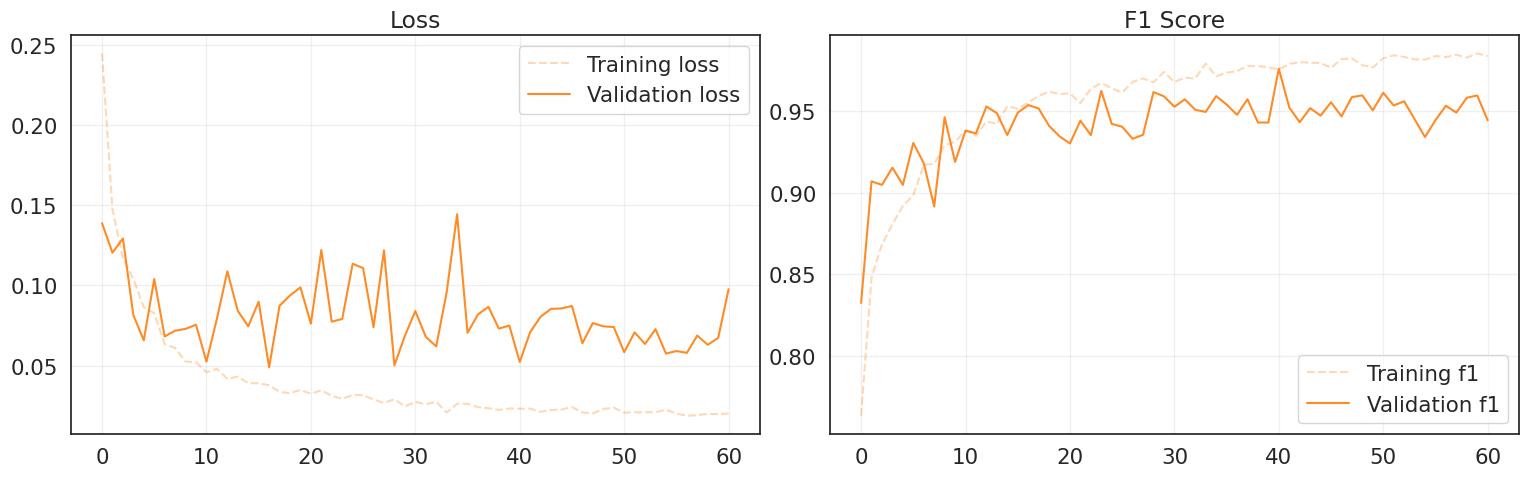

In [101]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9761
Precision over the validation set: 0.9766
Recall over the validation set: 0.9761
F1 score over the validation set: 0.9762


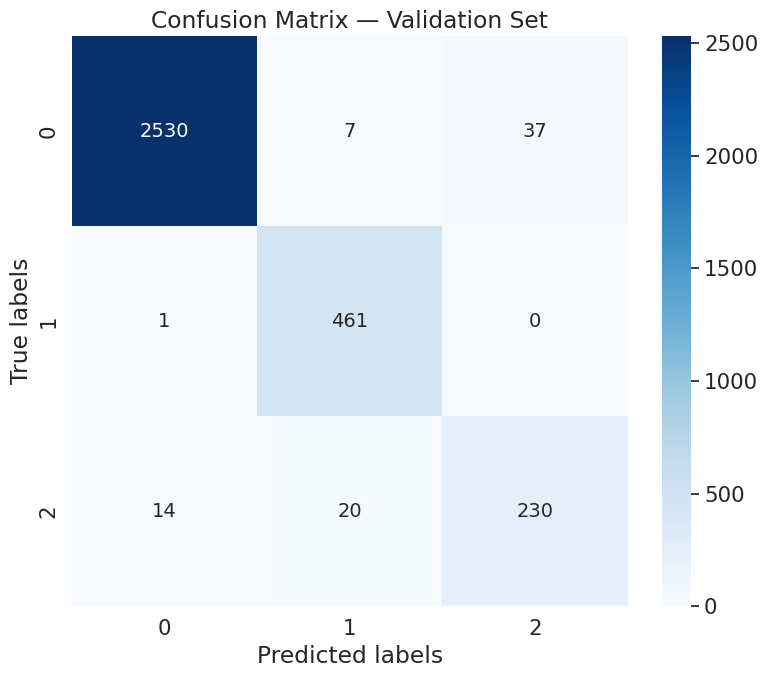

In [102]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device).float()  # Explicitly cast to float32

        # Forward pass: get model predictions
        logits = rnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

## 🍇 **Using the best model to classify the test dataset, probably can be handled better (avoid to run)**

In [103]:
from google.colab import files
#files.upload()

In [104]:
model_path = f"./models/{EXPERIMENT_NAME}_model.pt"
print(model_path)

./models/LSTM_True_ws32_bs64_stride4_lr0.001_gamma1.75_l10.0_l20.0001_patience20_hidden128_layers2_dropout0.3_jTrue_aTrue_reluFalse_model.pt


##### Run all of this

In [105]:

# remember to set correct values here
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1],
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=BIDIRECTIONAL,
    rnn_type=ARCHITECTURE,
    use_attention=ATTENTION,
    use_relu=RELU
).to(device)
rnn_model.load_state_dict(torch.load(model_path))#insert name of the model to load
print("Best performing model in the word with absolutely no overfitting loaded successfully.")

Best performing model in the word with absolutely no overfitting loaded successfully.


In [106]:
all_test_predictions = []
rnn_model.eval() # Ensure model is in evaluation mode
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device).float()
        logits = rnn_model(xb)
        predictions = logits.argmax(dim=1).cpu().numpy()
        all_test_predictions.append(predictions)

# Concatenate all predictions
all_test_predictions = np.concatenate(all_test_predictions)

print(f"Generated {len(all_test_predictions)} predictions for the test set.")

Generated 43692 predictions for the test set.


In [107]:
label_inverse_mapping = {v: k for k, v in label_mapping.items()}

# Create a DataFrame to store test predictions along with their original sample_index
test_pred_df = pd.DataFrame({
    'sample_index_sequence': range(len(all_test_predictions)), # Create a unique ID for each sequence
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
test_pred_df['predicted_label_str'] = test_pred_df['predicted_label_int'].map(label_inverse_mapping)

print(test_pred_df.head())


   sample_index_sequence  predicted_label_int predicted_label_str
0                      0                    2           high_pain
1                      1                    2           high_pain
2                      2                    2           high_pain
3                      3                    2           high_pain
4                      4                    0             no_pain


In [108]:
def get_sample_indices_for_sequences(df, window, stride):
    sample_indices = []
    for uid in df['sample_index'].unique():
        user_df = df[df['sample_index'] == uid]
        num_timesteps = len(user_df)

        # Calculate number of sequences generated for this user, similar to build_sequences
        # Need to consider padding that was applied in build_sequences
        padding_len = (window - (num_timesteps % window)) % window
        padded_num_timesteps = num_timesteps + padding_len

        idx = 0
        while idx + window <= padded_num_timesteps:
            sample_indices.append(uid)
            idx += stride
    return np.array(sample_indices)

# Get the original sample_index for each sequence generated for X_test
test_seq_original_sample_indices = get_sample_indices_for_sequences(df_test, WINDOW_SIZE, STRIDE)

# Verify that the number of original sample indices matches the number of predictions
assert len(test_seq_original_sample_indices) == len(all_test_predictions), \
    "Mismatch between number of sequences and number of predictions."

# Create a DataFrame that maps predictions to their original sample_index
predictions_with_original_index_df = pd.DataFrame({
    'sample_index': test_seq_original_sample_indices,
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
predictions_with_original_index_df['predicted_label_str'] = predictions_with_original_index_df['predicted_label_int'].map(label_inverse_mapping)

print("Predictions mapped to original sample indices:")
print(predictions_with_original_index_df.head())
print("\nDataFrame Info:")
predictions_with_original_index_df.info()

Predictions mapped to original sample indices:
   sample_index  predicted_label_int predicted_label_str
0             0                    2           high_pain
1             0                    2           high_pain
2             0                    2           high_pain
3             0                    2           high_pain
4             0                    0             no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43692 entries, 0 to 43691
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   sample_index         43692 non-null  int64 
 1   predicted_label_int  43692 non-null  int64 
 2   predicted_label_str  43692 non-null  object
dtypes: int64(2), object(1)
memory usage: 1.0+ MB


In [109]:
def get_sample_indices_for_sequences(df, window, stride):
    sample_indices = []
    # Feature columns are needed only to determine the number of original timesteps per user
    feature_columns = [col for col in df.columns if col.startswith('pain_survey_')] + \
                      [col for col in df.columns if col.startswith('joint_')] + \
                      ['has_any_disability']

    for uid in df['sample_index'].unique():
        user_df = df[df['sample_index'] == uid]
        num_timesteps = len(user_df) # This is the effective length of `temp` before padding in build_sequences

        # Calculate padding length consistent with build_sequences logic
        padding_len = (window - (num_timesteps % window)) % window

        # Total length of the series after conceptual padding
        total_len_after_padding = num_timesteps + padding_len

        idx = 0
        while idx + window <= total_len_after_padding:
            sample_indices.append(uid)
            idx += stride
    return np.array(sample_indices)

# Corrected window and stride based on the actual number of sequences generated for X_test
# (1300 sequences for 100 users with 160 timesteps each implies 13 sequences/user)
# For 160 timesteps, window=40, stride=10 produces (160 - 40) / 10 + 1 = 13 sequences.
window_for_test_seq_gen = WINDOW_SIZE # Use the global WINDOW_SIZE (80)
stride_for_test_seq_gen = STRIDE # Use the global STRIDE (20)

# Get the original sample_index for each sequence generated for X_test
test_seq_original_sample_indices = get_sample_indices_for_sequences(df_test, window_for_test_seq_gen, stride_for_test_seq_gen)

# Verify that the number of original sample indices matches the number of predictions
assert len(test_seq_original_sample_indices) == len(all_test_predictions), \
    "Mismatch between number of sequences and number of predictions."

# Create a DataFrame that maps predictions to their original sample_index
predictions_with_original_index_df = pd.DataFrame({
    'sample_index': test_seq_original_sample_indices,
    'predicted_label_int': all_test_predictions
})

# Map integer predictions back to string labels
predictions_with_original_index_df['predicted_label_str'] = predictions_with_original_index_df['predicted_label_int'].map(label_inverse_mapping)

print("Predictions mapped to original sample indices:")
print(predictions_with_original_index_df.head())
print("\nDataFrame Info:")
predictions_with_original_index_df.info()

Predictions mapped to original sample indices:
   sample_index  predicted_label_int predicted_label_str
0             0                    2           high_pain
1             0                    2           high_pain
2             0                    2           high_pain
3             0                    2           high_pain
4             0                    0             no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43692 entries, 0 to 43691
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   sample_index         43692 non-null  int64 
 1   predicted_label_int  43692 non-null  int64 
 2   predicted_label_str  43692 non-null  object
dtypes: int64(2), object(1)
memory usage: 1.0+ MB


In [110]:
final_predictions = predictions_with_original_index_df.groupby('sample_index')['predicted_label_str'].agg(lambda x: x.mode()[0]).reset_index()

# Rename the columns to match the submission format
final_predictions.columns = ['sample_index', 'label']

# Format sample_index to have 3 digits, padded with leading zeros
final_predictions['sample_index'] = final_predictions['sample_index'].astype(str).str.zfill(3)


print("Final predictions grouped by sample_index:")
print(final_predictions.head())
print("\nDataFrame Info:")
final_predictions.info()

Final predictions grouped by sample_index:
  sample_index    label
0          000  no_pain
1          001  no_pain
2          002  no_pain
3          003  no_pain
4          004  no_pain

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   sample_index  1324 non-null   object
 1   label         1324 non-null   object
dtypes: object(2)
memory usage: 20.8+ KB


In [111]:
final_predictions.to_csv(f'submission_{EXPERIMENT_NAME}_f1score{val_acc:.4f}.csv', index=False)
print(f'submission_{EXPERIMENT_NAME}_f1score{val_acc:.4f}.csv created successfully.')

submission_LSTM_True_ws32_bs64_stride4_lr0.001_gamma1.75_l10.0_l20.0001_patience20_hidden128_layers2_dropout0.3_jTrue_aTrue_reluFalse_f1score0.9761.csv created successfully.


## ❌ **Let's do some hyprland tuning (be carefull still need to be cleaned)**

In [ ]:
def k_shuffle_split_cross_validation_round_rnn(df, epochs, criterion, device,
                            k, n_val_users, n_test_users, batch_size, hidden_layers, hidden_size, learning_rate, dropout_rate,
                            window_size, stride, rnn_type, bidirectional= True, activation_function_type='None',
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name="",
                            lr_scheduler_patience=20, lr_scheduler_factor=0.1, gamma=1.5):
    """
    Perform K-fold shuffle split cross-validation with user-based splitting for time series data.

    Args:
        df: DataFrame with columns ['sample_index', 'label', 'pain_survey_X', 'joint_XX', 'has_any_disability']
        epochs: Number of training epochs
        criterion: Loss function (will be replaced by FocalLoss within the function)
        device: torch.device for computation
        k: Number of cross-validation splits
        n_val_users: Number of users for validation set
        n_test_users: Number of users for test set
        batch_size: Batch size for training
        hidden_layers: Number of recurrent layers
        hidden_size: Hidden state dimensionality
        learning_rate: Learning rate for optimizer
        dropout_rate: Dropout rate
        window_size: Length of sliding windows
        stride: Step size for sliding windows
        rnn_type: Type of RNN ('RNN', 'LSTM', 'GRU')
        bidirectional: Whether to use bidirectional RNN
        activation_function_type: Type of activation function to use ('None', 'ReLU', 'LeakyReLU', 'ELU')
        l1_lambda: L1 regularization coefficient (if used)
        l2_lambda: L2 regularization coefficient (weight_decay)
        patience: Early stopping patience
        evaluation_metric: Metric to monitor for early stopping
        mode: 'max' or 'min' for evaluation metric
        restore_best_weights: Whether to restore best weights after training
        writer: TensorBoard writer
        verbose: Verbosity level
        seed: Random seed
        experiment_name: Name for experiment logging
        lr_scheduler_patience (int): Number of epochs with no improvement after which learning rate will be reduced.
        lr_scheduler_factor (float): Factor by which the learning rate will be reduced.
        gamma (float): Gamma parameter for FocalLoss.

    Returns:
        fold_losses: Dict with validation losses for each split
        fold_metrics: Dict with validation F1 scores for each split
        best_scores: Dict with best F1 score for each split plus mean and std
    """

    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}

    # Get model architecture parameters
    # Use global input_shape and num_classes derived from the initial data processing
    in_features = input_shape[-1] # From X_train.shape[1:] computed earlier
    num_classes_model = num_classes # From num_classes computed earlier

    # Initialise model architecture
    model = RecurrentClassifier(
        input_size=in_features,
        hidden_size=hidden_size,
        num_layers=hidden_layers,
        num_classes=num_classes_model, # Use the global num_classes
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type,
        activation_function_type=activation_function_type # Pass the new parameter here
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())

    # Extract user labels from the original df for stratification
    # Ensure original string labels are used before integer mapping for stratification
    user_labels_full = df[['sample_index', 'label']].drop_duplicates().set_index('sample_index')['label']

    # Iterate through K random splits
    for split_idx in range(k):

        if verbose > 0:
            print(f"Split {split_idx+1}/{k}")

        # Get unique user IDs
        unique_users = df['sample_index'].unique()

        # Create a stratify_labels array corresponding to unique_users
        stratify_labels_for_users = user_labels_full.loc[unique_users].values

        # First split: Separate out test_users (CV test set) from the rest (temp_train_val_users)
        # Use N_TEST_USERS for the test set and stratify
        temp_train_val_users, test_users = train_test_split(
            unique_users,
            test_size=n_test_users,
            stratify=stratify_labels_for_users,
            random_state=seed + split_idx
        )

        # Create stratify_labels for the temp_train_val_users
        stratify_labels_for_temp = user_labels_full.loc[temp_train_val_users].values

        # Second split: Separate temp_train_val_users into train_users and val_users
        # Use N_VAL_USERS for the validation set and stratify
        train_users, val_users = train_test_split(
            temp_train_val_users,
            test_size=n_val_users,
            stratify=stratify_labels_for_temp,
            random_state=seed + split_idx
        )

        # Split the dataset into training, validation, and test sets based on user IDs
        df_train = df[df['sample_index'].isin(train_users)].copy()
        df_val = df[df['sample_index'].isin(val_users)].copy()
        # For cross-validation, df_test_cv needs to be from the train_df to have labels for evaluation
        df_test_cv = df[df['sample_index'].isin(test_users)].copy()

        # Define a mapping of activity names to integer labels - using the global label_mapping
        df_train['label'] = df_train['label'].map(label_mapping)
        df_val['label'] = df_val['label'].map(label_mapping)
        if not df_test_cv.empty:
            df_test_cv['label'] = df_test_cv['label'].map(label_mapping)

        # Define the columns to be normalised - these are the 'joint_' columns
        joint_columns = [col for col in df_train.columns if col.startswith('joint_')]

        # Calculate the minimum and maximum values from the training data only
        mins = df_train[joint_columns].min()
        maxs = df_train[joint_columns].max()

        # Apply normalisation to the specified columns in all datasets
        for column in joint_columns:
            col_min = mins[column]
            col_max = maxs[column]

            # Check for constant columns to prevent division by zero
            if col_max == col_min:
                if verbose > 0:
                    print(f"  Warning: Column '{column}' has constant values in df_train. Setting to 0 after 'normalization'.")
                df_train[column] = 0.0
                df_val[column] = 0.0
                df_test_cv[column] = 0.0
            else:
                df_train[column] = (df_train[column] - col_min) / (col_max - col_min)
                df_val[column] = (df_val[column] - col_min) / (col_max - col_min)
                df_test_cv[column] = (df_test_cv[column] - col_min) / (col_max - col_min)

        # First, fill any NaN values that might have been introduced unexpectedly.
        df_train.fillna(0, inplace=True);
        df_val.fillna(0, inplace=True);
        df_test_cv.fillna(0, inplace=True);
        # Replace inf values which might result from 0/0 operations if not caught by the constant column check
        df_train.replace([np.inf, -np.inf], 0, inplace=True);
        df_val.replace([np.inf, -np.inf], 0, inplace=True);
        df_test_cv.replace([np.inf, -np.inf], 0, inplace=True);


        # Build sequences using the existing build_sequences function
        X_train, y_train_sequences = build_sequences(df_train, window=window_size, stride=stride)
        X_val, y_val = build_sequences(df_val, window=window_size, stride=stride)
        X_test, y_test = build_sequences(df_test_cv, window=window_size, stride=stride)

        # Convert any remaining NaNs or Infs to finite numbers
        X_train = np.nan_to_num(X_train)
        X_val = np.nan_to_num(X_val)
        X_test = np.nan_to_num(X_test)

        if verbose > 0:
            print(f"  Training sequences shape: {X_train.shape}")
            print(f"  Validation sequences shape: {X_val.shape}")
            print(f"  CV Test sequences shape: {X_test.shape}")

        # Create PyTorch datasets, explicitly casting to .float()
        train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train_sequences))
        val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))
        test_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))

        # Calculate class weights for handling imbalanced datasets FOR THIS FOLD
        class_counts_fold = np.bincount(y_train_sequences)
        class_weights_fold = 1.0 / (class_counts_fold + 1e-5)
        class_weights_fold = class_weights_fold / class_weights_fold.sum() * num_classes_model
        class_weights_fold = torch.tensor(class_weights_fold, dtype=torch.float32).to(device)
        if verbose > 0:
            print("  Calculated Fold Class Weights (for FocalLoss alpha):", class_weights_fold)

        # --- Start of weighted sampling logic ---
        weights_vector_fold = []

        # Get user-level information from the current df_train, retaining original string labels
        user_level_info_df_raw_labels = df[['sample_index', 'has_any_disability', 'label']].drop_duplicates(subset=['sample_index']).set_index('sample_index')
        user_level_info_df_raw_labels = user_level_info_df_raw_labels[user_level_info_df_raw_labels.index.isin(df_train['sample_index'].unique())]

        # Calculate weights for 'pirate' and 'no_pirate' users in this fold using ORIGINAL STRING LABELS
        pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 1]
        pirate_label_counts_fold = pirate_users_info_fold['label'].value_counts()
        total_pirate_users_fold = pirate_label_counts_fold.sum()
        weights_pirate_fold = {
            label: (1.0 / count) * (total_pirate_users_fold / len(pirate_label_counts_fold))
            for label, count in pirate_label_counts_fold.items()
        } if len(pirate_label_counts_fold) > 0 else {} # Handle case where no pirate users in fold
        if sum(weights_pirate_fold.values()) > 0:
            sum_weights_pirate_fold = sum(weights_pirate_fold.values())
            weights_pirate_fold = {label: weight / sum_weights_pirate_fold for label, weight in weights_pirate_fold.items()}


        no_pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 0]
        no_pirate_label_counts_fold = no_pirate_users_info_fold['label'].value_counts()
        total_no_pirate_users_fold = no_pirate_label_counts_fold.sum()
        weights_no_pirate_fold = {
            label: (1.0 / count) * (total_no_pirate_users_fold / len(no_pirate_label_counts_fold))
            for label, count in no_pirate_label_counts_fold.items()
        } if len(no_pirate_label_counts_fold) > 0 else {} # Handle case where no non-pirate users in fold
        if sum(weights_no_pirate_fold.values()) > 0:
            sum_weights_no_pirate_fold = sum(weights_no_pirate_fold.values())
            weights_no_pirate_fold = {label: weight / sum_weights_no_pirate_fold for label, weight in weights_no_pirate_fold.items()}


        # Reconstruct the mapping from sequence index in train_ds to its original sample_index (user_id)
        original_sample_indices_for_train_sequences_fold = []
        for user_id in df_train['sample_index'].unique():
            user_data_len = len(df_train[df_train['sample_index'] == user_id])
            padding_len = (window_size - (user_data_len % window_size)) % window_size
            total_len_after_padding = user_data_len + padding_len

            idx = 0
            while idx + window_size <= total_len_after_padding:
                original_sample_indices_for_train_sequences_fold.append(user_id)
                idx += stride

        if len(original_sample_indices_for_train_sequences_fold) != len(train_ds):
            # This error check is critical. If it fails, something is wrong with sequence generation consistency.
            raise ValueError(
                f"Mismatch in number of sequences for weight calculation and actual train_ds length for split {split_idx}.\n"
                f"Expected {len(train_ds)} sequences, but got {len(original_sample_indices_for_train_sequences_fold)}."
                "This indicates an inconsistency in how sequences are generated or accounted for."
            )

        for sequence_original_sample_index in original_sample_indices_for_train_sequences_fold:
            has_disability = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'has_any_disability']
            # Retrieve the original string label directly
            original_string_label = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'label']

            if has_disability:
                # Use .get with a default value (e.g., 1.0) to prevent KeyError if a label is missing from weights_pirate_fold
                weight = weights_pirate_fold.get(original_string_label, 1.0)
            else:
                weight = weights_no_pirate_fold.get(original_string_label, 1.0)

            weights_vector_fold.append(weight)

        weights_vector_fold = torch.tensor(weights_vector_fold, dtype=torch.float32)

        weighted_sampler_fold = WeightedRandomSampler(weights=weights_vector_fold, num_samples=len(train_ds), replacement=True)

        # --- End of weighted sampling logic ---

        # Create data loaders, passing the weighted_sampler_fold to train_loader
        # shuffle=False when using a sampler
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=False, drop_last=False, sampler=weighted_sampler_fold)
        val_loader   = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)
        test_loader  = make_loader(test_ds, batch_size=batch_size, shuffle=False, drop_last=False)

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Create directory for model checkpoints
        os.makedirs(f"models/{experiment_name}", exist_ok=True)

        # Re-initialize criterion with fold-specific class weights and FocalLoss
        criterion_per_fold = FocalLoss(alpha=class_weights_fold, gamma=gamma, reduction='mean') # Use gamma parameter here

        # Initialize ReduceLROnPlateau scheduler for this fold
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode=mode,
            factor=lr_scheduler_factor,
            patience=lr_scheduler_patience,
            min_lr=1e-7 # Define a minimum learning rate
        )

        # Train model on current split
        model, training_history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion_per_fold, # Use fold-specific criterion
            optimizer=optimizer,
            scaler=split_scaler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=restore_best_weights,
            experiment_name=experiment_name+"/split_"+str(split_idx),
            scheduler=scheduler # Pass the scheduler to the fit function
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print(f"Best score: {best_scores['mean']:.4f}\u00B1{best_scores['std']:.4f}")

    return fold_losses, fold_metrics, best_scores


def grid_search_cv_rnn(df, param_grid, fixed_params, cv_params, verbose=True):
    """
    Execute grid search with K-shuffle-split cross-validation for RNN models on time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        param_grid: Dict of parameters to test, e.g. {'batch_size': [16, 32], 'rnn_type': ['LSTM', 'GRU']}
        fixed_params: Dict of fixed hyperparameters (hidden_size, learning_rate, window_size, stride, etc.)
        cv_params: Dict of CV settings (epochs, k, patience, criterion, scaler, device, etc.)
        verbose: Print progress for each configuration

    Returns:
        results: Dict with scores for each configuration
        best_config: Dict with best hyperparameter combination
        best_score: Best mean F1 score achieved
    """
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    combinations = list(product(*param_values))

    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = "_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Execute cross-validation
        _, _, fold_scores = k_shuffle_split_cross_validation_round_rnn(
            df=df,
            experiment_name=config_str,
            **run_params,
            **cv_params
        )

        # Store results
        results[config_str] = fold_scores

        # Track best configuration
        if fold_scores["mean"] > best_score:
            best_score = fold_scores["mean"]
            best_config = current_config.copy()
            if verbose:
                print("  NEW BEST SCORE!")

        if verbose:
            print(f"  F1 Score: {fold_scores['mean']:.4f}\u00B1{fold_scores['std']:.4f}")

    return results, best_config, best_score


def plot_top_configurations_rnn(results, k_splits, top_n=5, figsize=(14, 7)):
    """
    Visualise top N RNN configurations with boxplots of F1 scores across CV splits.

    Args:
        results: Dict of results from grid_search_cv_rnn
        k_splits: Number of CV splits used
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    # Sort by mean score
    config_scores = {name: data['mean'] for name, data in results.items()}
    sorted_configs = sorted(config_scores.items(), key=lambda x: x[1], reverse=True)

    # Select top N
    top_configs = sorted_configs[:min(top_n, len(sorted_configs))]

    # Prepare boxplot data
    boxplot_data = []
    labels = []

    # Define a dictionary for replacements, ordered to handle prefixes correctly
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nHL=',
        'hidden_size_': '\nHS=',
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'rnn_type_': '\nRNN=',
        'bidirectional_': '\nBIDIR=',
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2=',
        'activation_function_type_': '\nACT=' # Updated key
    }

    # Replacements for separators
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nHL=',
        '_hidden_size_': '\nHS=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_rnn_type_': '\nRNN=',
        '_bidirectional_': '\nBIDIR=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_activation_function_type_': '\nACT=', # Updated key
        '_': ''
    }

    for config_name, mean_score in top_configs:
        # Extract best score from each split (auto-detect number of splits)
        split_scores = []
        for i in range(k_splits):
            if f'split_{i}' in results[config_name]:
                split_scores.append(results[config_name][f'split_{i}']) # Access the first element if it's a list
        boxplot_data.append(split_scores)

        # Verify we have the expected number of splits
        if len(split_scores) != k_splits:
            print(f"Warning: Config {config_name} has {len(split_scores)} splits, expected {k_splits}")

        # Create readable label using the replacements dictionary
        readable_label = config_name
        for old, new in replacements.items():
            readable_label = readable_label.replace(old, new)

        # Apply separator replacements
        for old, new in separator_replacements.items():
             readable_label = readable_label.replace(old, new)

        labels.append(f"{readable_label}\n(\u03BC={mean_score:.3f})")

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    bp = ax.boxplot(boxplot_data, labels=labels, patch_artist=True,
                    showmeans=True, meanline=True)

    # Styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)

    # Highlight best configuration
    if labels:
        ax.get_xticklabels()[0].set_fontweight('bold')

    ax.set_ylabel('F1 Score')
    ax.set_xlabel('Configuration')
    ax.set_title(f'Top {len(top_configs)} RNN Configurations - F1 Score Distribution Across {k_splits} Splits')
    ax.grid(alpha=0.3, axis='y')

    plt.xticks(rotation=0, ha='center')
    plt.tight_layout()
    plt.show()

In [ ]:
K=2 # Setting K to 2 to have enough splits for mean/std. It was 1 previously.
# Define parameters to search
param_grid = {
    'window_size': [40],
    'stride': [4, 8],
    'batch_size': [128],
    'dropout_rate': [0.2],
    'hidden_layers': [2], # Expanded range for hidden layers
    'hidden_size': [256], # Expanded range for hidden size
    'l1_lambda': [0.000],
    'l2_lambda': [0.000],
    'gamma': [0.5, 1.0, 1.5, 2.0, 2.5, 3.0], # Expanded range for gamma
    'use_relu': [False, True]
}

# Fixed hyperparameters (not being tuned)
fixed_params = {
    'rnn_type': 'LSTM',
    'learning_rate': 1e-3,
    'bidirectional': True
}

# Cross-validation settings
cv_params = {
    'epochs': EPOCHS,
    'criterion': CRITERION, # This will be ignored as FocalLoss is initiated inside k_shuffle_split_cross_validation_round_rnn
    'device': device,
    'k': K,
    'n_val_users': 60, # Using N_VAL_USERS global variable
    'n_test_users': 60,
    'patience': PATIENCE,
    'verbose': 0,
    'seed': SEED,
    'lr_scheduler_patience': 20,
    'lr_scheduler_factor': 0.2,
}

# Execute search
results, best_config, best_score = grid_search_cv_rnn(
    df=df,
    param_grid=param_grid,
    fixed_params=fixed_params,
    cv_params=cv_params
)



Configuration 1/72:
  window_size: 24
  stride: 4
  batch_size: 64
  dropout_rate: 0.2
  hidden_layers: 2
  hidden_size: 256
  l1_lambda: 0.0001
  l2_lambda: 0.0001
  gamma: 2
Training 1000 epochs...
Early stopping triggered after 142 epochs.
Best model restored from epoch 42 with val_f1 0.8330
Training 1000 epochs...


In [ ]:
def k_shuffle_split_cross_validation_round_rnn(df, epochs, criterion, device,
                            k, n_val_users, n_test_users, batch_size, hidden_layers, hidden_size, learning_rate, dropout_rate,
                            window_size, stride, rnn_type, bidirectional= True, activation_function_type='None',
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name="",
                            lr_scheduler_patience=20, lr_scheduler_factor=0.1, gamma=1.5):
    """
    Perform K-fold shuffle split cross-validation with user-based splitting for time series data.

    Args:
        df: DataFrame with columns ['sample_index', 'label', 'pain_survey_X', 'joint_XX', 'has_any_disability']
        epochs: Number of training epochs
        criterion: Loss function (will be replaced by FocalLoss within the function)
        device: torch.device for computation
        k: Number of cross-validation splits
        n_val_users: Number of users for validation set
        n_test_users: Number of users for test set
        batch_size: Batch size for training
        hidden_layers: Number of recurrent layers
        hidden_size: Hidden state dimensionality
        learning_rate: Learning rate for optimizer
        dropout_rate: Dropout rate
        window_size: Length of sliding windows
        stride: Step size for sliding windows
        rnn_type: Type of RNN ('RNN', 'LSTM', 'GRU')
        bidirectional: Whether to use bidirectional RNN
        activation_function_type: Type of activation function to use ('None', 'ReLU', 'LeakyReLU', 'ELU')
        l1_lambda: L1 regularization coefficient (if used)
        l2_lambda: L2 regularization coefficient (weight_decay)
        patience: Early stopping patience
        evaluation_metric: Metric to monitor for early stopping
        mode: 'max' or 'min' for evaluation metric
        restore_best_weights: Whether to restore best weights after training
        writer: TensorBoard writer
        verbose: Verbosity level
        seed: Random seed
        experiment_name: Name for experiment logging
        lr_scheduler_patience (int): Number of epochs with no improvement after which learning rate will be reduced.
        lr_scheduler_factor (float): Factor by which the learning rate will be reduced.
        gamma (float): Gamma parameter for FocalLoss.

    Returns:
        fold_losses: Dict with validation losses for each split
        fold_metrics: Dict with validation F1 scores for each split
        best_scores: Dict with best F1 score for each split plus mean and std
    """

    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}

    # Get model architecture parameters
    # Use global input_shape and num_classes derived from the initial data processing
    in_features = input_shape[-1] # From X_train.shape[1:] computed earlier
    num_classes_model = num_classes # From num_classes computed earlier

    # Initialise model architecture
    model = RecurrentClassifier(
        input_size=in_features,
        hidden_size=hidden_size,
        num_layers=hidden_layers,
        num_classes=num_classes_model, # Use the global num_classes
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type,
        # activation_function_type=activation_function_type # Pass the new parameter here
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())

    # Extract user labels and has_any_disability from the original df for stratification
    user_strat_info = df[['sample_index', 'label', 'has_any_disability']].drop_duplicates().set_index('sample_index')

    # Iterate through K random splits
    for split_idx in range(k):

        if verbose > 0:
            print(f"Split {split_idx+1}/{k}")

        # Get unique user IDs
        unique_users = df['sample_index'].unique()

        # Create a combined stratification key for each unique user
        # This ensures stratification considers both label and disability status
        combined_strat_key_for_users = user_strat_info.loc[unique_users].apply(
            lambda row: f"{row['label']}_{row['has_any_disability']}", axis=1
        ).values

        # First split: Separate out test_users (CV test set) from the rest (temp_train_val_users)
        # Use N_TEST_USERS for the test set and stratify by the combined key
        temp_train_val_users, test_users = train_test_split(
            unique_users,
            test_size=n_test_users,
            stratify=combined_strat_key_for_users,
            random_state=seed + split_idx
        )

        # Create combined stratification key for the temp_train_val_users
        combined_strat_key_for_temp = user_strat_info.loc[temp_train_val_users].apply(
            lambda row: f"{row['label']}_{row['has_any_disability']}", axis=1
        ).values

        # Second split: Separate temp_train_val_users into train_users and val_users
        # Use N_VAL_USERS for the validation set and stratify by the combined key
        train_users, val_users = train_test_split(
            temp_train_val_users,
            test_size=n_val_users,
            stratify=combined_strat_key_for_temp,
            random_state=seed + split_idx
        )

        # Split the dataset into training, validation, and test sets based on user IDs
        df_train = df[df['sample_index'].isin(train_users)].copy()
        df_val = df[df['sample_index'].isin(val_users)].copy()
        # For cross-validation, df_test_cv needs to be from the train_df to have labels for evaluation
        df_test_cv = df[df['sample_index'].isin(test_users)].copy()

        # Define a mapping of activity names to integer labels - using the global label_mapping
        df_train['label'] = df_train['label'].map(label_mapping)
        df_val['label'] = df_val['label'].map(label_mapping)
        if not df_test_cv.empty:
            df_test_cv['label'] = df_test_cv['label'].map(label_mapping)

        # Define the columns to be normalised - these are the 'joint_' columns
        joint_columns = [col for col in df_train.columns if col.startswith('joint_')]

        # Calculate the minimum and maximum values from the training data only
        mins = df_train[joint_columns].min()
        maxs = df_train[joint_columns].max()

        # Apply normalisation to the specified columns in all datasets
        for column in joint_columns:
            col_min = mins[column]
            col_max = maxs[column]

            # Check for constant columns to prevent division by zero
            if col_max == col_min:
                if verbose > 0:
                    print(f"  Warning: Column '{column}' has constant values in df_train. Setting to 0 after 'normalization'.")
                df_train[column] = 0.0
                df_val[column] = 0.0
                df_test_cv[column] = 0.0
            else:
                df_train[column] = (df_train[column] - col_min) / (col_max - col_min)
                df_val[column] = (df_val[column] - col_min) / (col_max - col_min)
                df_test_cv[column] = (df_test_cv[column] - col_min) / (col_max - col_min)

        # First, fill any NaN values that might have been introduced unexpectedly.
        df_train.fillna(0, inplace=True);
        df_val.fillna(0, inplace=True);
        df_test_cv.fillna(0, inplace=True);
        # Replace inf values which might result from 0/0 operations if not caught by the constant column check
        df_train.replace([np.inf, -np.inf], 0, inplace=True);
        df_val.replace([np.inf, -np.inf], 0, inplace=True);
        df_test_cv.replace([np.inf, -np.inf], 0, inplace=True);


        # Build sequences using the existing build_sequences function
        X_train, y_train_sequences = build_sequences(df_train, window=window_size, stride=stride)
        X_val, y_val = build_sequences(df_val, window=window_size, stride=stride)
        X_test, y_test = build_sequences(df_test_cv, window=window_size, stride=stride)

        # Convert any remaining NaNs or Infs to finite numbers
        X_train = np.nan_to_num(X_train)
        X_val = np.nan_to_num(X_val)
        X_test = np.nan_to_num(X_test)

        if verbose > 0:
            print(f"  Training sequences shape: {X_train.shape}")
            print(f"  Validation sequences shape: {X_val.shape}")
            print(f"  CV Test sequences shape: {X_test.shape}")

        # Create PyTorch datasets, explicitly casting to .float()
        train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train_sequences))
        val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))
        test_ds  = TensorDataset(torch.from_numpy(X_test).float(), torch.from_numpy(y_test))

        # Calculate class weights for handling imbalanced datasets FOR THIS FOLD
        class_counts_fold = np.bincount(y_train_sequences)
        class_weights_fold = 1.0 / (class_counts_fold + 1e-5)
        class_weights_fold = class_weights_fold / class_weights_fold.sum() * num_classes_model
        class_weights_fold = torch.tensor(class_weights_fold, dtype=torch.float32).to(device)
        if verbose > 0:
            print("  Calculated Fold Class Weights (for FocalLoss alpha):", class_weights_fold)

        # --- Start of weighted sampling logic ---
        weights_vector_fold = []

        # Get user-level information from the current df_train, retaining original string labels
        user_level_info_df_raw_labels = df[['sample_index', 'has_any_disability', 'label']].drop_duplicates(subset=['sample_index']).set_index('sample_index')
        user_level_info_df_raw_labels = user_level_info_df_raw_labels[user_level_info_df_raw_labels.index.isin(df_train['sample_index'].unique())]

        # Calculate weights for 'pirate' and 'no_pirate' users in this fold using ORIGINAL STRING LABELS
        pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 1]
        pirate_label_counts_fold = pirate_users_info_fold['label'].value_counts()
        total_pirate_users_fold = pirate_label_counts_fold.sum()
        weights_pirate_fold = {
            label: (1.0 / count) * (total_pirate_users_fold / len(pirate_label_counts_fold))
            for label, count in pirate_label_counts_fold.items()
        } if len(pirate_label_counts_fold) > 0 else {} # Handle case where no pirate users in fold
        if sum(weights_pirate_fold.values()) > 0:
            sum_weights_pirate_fold = sum(weights_pirate_fold.values())
            weights_pirate_fold = {label: weight / sum_weights_pirate_fold for label, weight in weights_pirate_fold.items()}


        no_pirate_users_info_fold = user_level_info_df_raw_labels[user_level_info_df_raw_labels['has_any_disability'] == 0]
        no_pirate_label_counts_fold = no_pirate_users_info_fold['label'].value_counts()
        total_no_pirate_users_fold = no_pirate_label_counts_fold.sum()
        weights_no_pirate_fold = {
            label: (1.0 / count) * (total_no_pirate_users_fold / len(no_pirate_label_counts_fold))
            for label, count in no_pirate_label_counts_fold.items()
        } if len(no_pirate_label_counts_fold) > 0 else {} # Handle case where no non-pirate users in fold
        if sum(weights_no_pirate_fold.values()) > 0:
            sum_weights_no_pirate_fold = sum(weights_no_pirate_fold.values())
            weights_no_pirate_fold = {label: weight / sum_weights_no_pirate_fold for label, weight in weights_no_pirate_fold.items()}


        # Reconstruct the mapping from sequence index in train_ds to its original sample_index (user_id)
        original_sample_indices_for_train_sequences_fold = []
        for user_id in df_train['sample_index'].unique():
            user_data_len = len(df_train[df_train['sample_index'] == user_id])
            padding_len = (window_size - (user_data_len % window_size)) % window_size
            total_len_after_padding = user_data_len + padding_len

            idx = 0
            while idx + window_size <= total_len_after_padding:
                original_sample_indices_for_train_sequences_fold.append(user_id)
                idx += stride

        if len(original_sample_indices_for_train_sequences_fold) != len(train_ds):
            # This error check is critical. If it fails, something is wrong with sequence generation consistency.
            raise ValueError(
                f"Mismatch in number of sequences for weight calculation and actual train_ds length for split {split_idx}.\n"
                f"Expected {len(train_ds)} sequences, but got {len(original_sample_indices_for_train_sequences_fold)}."
                "This indicates an inconsistency in how sequences are generated or accounted for."
            )

        for sequence_original_sample_index in original_sample_indices_for_train_sequences_fold:
            has_disability = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'has_any_disability']
            # Retrieve the original string label directly
            original_string_label = user_level_info_df_raw_labels.loc[sequence_original_sample_index, 'label']

            if has_disability:
                # Use .get with a default value (e.g., 1.0) to prevent KeyError if a label is missing from weights_pirate_fold
                weight = weights_pirate_fold.get(original_string_label, 1.0)
            else:
                weight = weights_no_pirate_fold.get(original_string_label, 1.0)

            weights_vector_fold.append(weight)

        weights_vector_fold = torch.tensor(weights_vector_fold, dtype=torch.float32)

        weighted_sampler_fold = WeightedRandomSampler(weights=weights_vector_fold, num_samples=len(train_ds), replacement=True)

        # --- End of weighted sampling logic ---

        # Create data loaders, passing the weighted_sampler_fold to train_loader
        # shuffle=False when using a sampler
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=False, drop_last=False, sampler=weighted_sampler_fold)
        val_loader   = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)
        test_loader  = make_loader(test_ds, batch_size=batch_size, shuffle=False, drop_last=False)

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Create directory for model checkpoints
        os.makedirs(f"models/{experiment_name}", exist_ok=True)

        # Re-initialize criterion with fold-specific class weights and FocalLoss
        criterion_per_fold = FocalLoss(alpha=class_weights_fold, gamma=gamma, reduction='mean') # Use gamma parameter here

        # Initialize ReduceLROnPlateau scheduler for this fold
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode=mode,
            factor=lr_scheduler_factor,
            patience=lr_scheduler_patience,
            min_lr=1e-7 # Define a minimum learning rate
        )

        # Train model on current split
        model, training_history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion_per_fold, # Use fold-specific criterion
            optimizer=optimizer,
            scaler=split_scaler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=restore_best_weights,
            experiment_name=experiment_name+"/split_"+str(split_idx),
            scheduler=scheduler # Pass the scheduler to the fit function
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print(f"Best score: {best_scores['mean']:.4f}\u00B1{best_scores['std']:.4f}")

    return fold_losses, fold_metrics, best_scores


def grid_search_cv_rnn(df, param_grid, fixed_params, cv_params, verbose=True):
    """
    Execute grid search with K-shuffle-split cross-validation for RNN models on time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        param_grid: Dict of parameters to test, e.g. {'batch_size': [16, 32], 'rnn_type': ['LSTM', 'GRU']}
        fixed_params: Dict of fixed hyperparameters (hidden_size, learning_rate, window_size, stride, etc.)
        cv_params: Dict of CV settings (epochs, k, patience, criterion, scaler, device, etc.)
        verbose: Print progress for each configuration

    Returns:
        results: Dict with scores for each configuration
        best_config: Dict with best hyperparameter combination
        best_score: Best mean F1 score achieved
    """
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    combinations = list(product(*param_values))

    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = "_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Execute cross-validation
        _, _, fold_scores = k_shuffle_split_cross_validation_round_rnn(
            df=df,
            experiment_name=config_str,
            **run_params,
            **cv_params
        )

        # Store results
        results[config_str] = fold_scores

        # Track best configuration
        if fold_scores["mean"] > best_score:
            best_score = fold_scores["mean"]
            best_config = current_config.copy()
            if verbose:
                print("  NEW BEST SCORE!")

        if verbose:
            print(f"  F1 Score: {fold_scores['mean']:.4f}\u00B1{fold_scores['std']:.4f}")

    return results, best_config, best_score


def plot_top_configurations_rnn(results, k_splits, top_n=5, figsize=(14, 7)):
    """
    Visualise top N RNN configurations with boxplots of F1 scores across CV splits.

    Args:
        results: Dict of results from grid_search_cv_rnn
        k_splits: Number of CV splits used
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    # Sort by mean score
    config_scores = {name: data['mean'] for name, data in results.items()}
    sorted_configs = sorted(config_scores.items(), key=lambda x: x[1], reverse=True)

    # Select top N
    top_configs = sorted_configs[:min(top_n, len(sorted_configs))]

    # Prepare boxplot data
    boxplot_data = []
    labels = []

    # Define a dictionary for replacements, ordered to handle prefixes correctly
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nHL=',
        'hidden_size_': '\nHS=',
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'rnn_type_': '\nRNN=',
        'bidirectional_': '\nBIDIR=',
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2=',
        'activation_function_type_': '\nACT=' # Updated key
    }

    # Replacements for separators
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nHL=',
        '_hidden_size_': '\nHS=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_rnn_type_': '\nRNN=',
        '_bidirectional_': '\nBIDIR=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_activation_function_type_': '\nACT=', # Updated key
        '_': ''
    }

    for config_name, mean_score in top_configs:
        # Extract best score from each split (auto-detect number of splits)
        split_scores = []
        for i in range(k_splits):
            if f'split_{i}' in results[config_name]:
                split_scores.append(results[config_name][f'split_{i}']) # Access the first element if it's a list
        boxplot_data.append(split_scores)

        # Verify we have the expected number of splits
        if len(split_scores) != k_splits:
            print(f"Warning: Config {config_name} has {len(split_scores)} splits, expected {k_splits}")

        # Create readable label using the replacements dictionary
        readable_label = config_name
        for old, new in replacements.items():
            readable_label = readable_label.replace(old, new)

        # Apply separator replacements
        for old, new in separator_replacements.items():
             readable_label = readable_label.replace(old, new)

        labels.append(f"{readable_label}\n(\u03BC={mean_score:.3f})")

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    bp = ax.boxplot(boxplot_data, labels=labels, patch_artist=True,
                    showmeans=True, meanline=True)

    # Styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)

    # Highlight best configuration
    if labels:
        ax.get_xticklabels()[0].set_fontweight('bold')

    ax.set_ylabel('F1 Score')
    ax.set_xlabel('Configuration')
    ax.set_title(f'Top {len(top_configs)} RNN Configurations - F1 Score Distribution Across {k_splits} Splits')
    ax.grid(alpha=0.3, axis='y')

    plt.xticks(rotation=0, ha='center')
    plt.tight_layout()
    plt.show()